# 07 · Tez Araç Kutusu: Grafikler, Marjlar, Sıralı / Sayım / Sansürlü Modeller, Panel Birim Kök

Grafik, marj, tablo aktarma, sıralı ve sayım modelleri, panel birim kök ve VAR.

**Öğreneceklerin**
1. Grafik çizmek ve Word raporuna **Şekil** olarak eklemek
2. `margins, at()` ile **koşullu tahmin ve etkiler**; `marginsplot`
3. Tabloyu Word / LaTeX / Excel'e aktarmak (`esttab using`)
4. Sıralı logit (ologit), sayım modelleri (poisson, nbreg) ve tobit
5. Panel birim kök testleri (LLC, IPS, Fisher) ve VAR

> ⚠️ Veriler **simüle edilmiştir**.

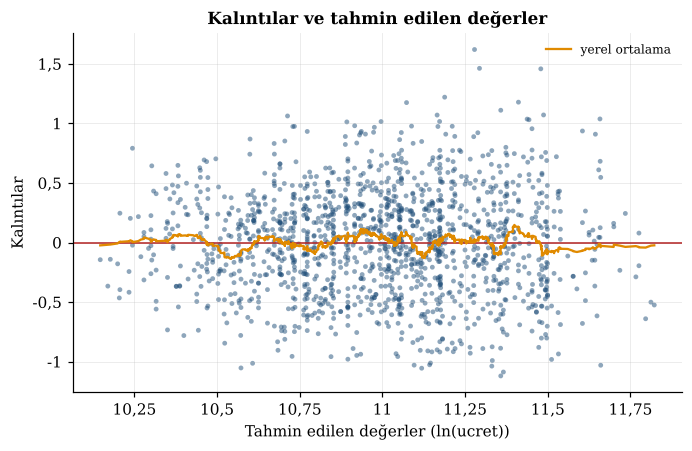

In [1]:
import numpy as np
import pandas as pd
import ekonometri as ek

ucret = ek.veri.yukle("ucret")
m = ek.ekk("np.log(ucret) ~ egitim + tecrube + I(tecrube**2) + C(cinsiyet)", ucret, kovaryans="HC1")
ek.kalinti_grafigi(m)          # Stata: rvfplot

## 1. Grafikler

Her grafik `Sekil` nesnesidir: `kaydet("dosya.png")` ile 300 dpi kaydedilir, `rapor.sekil_ekle()` ile Word raporuna numaralı şekil olarak girer. Eksenlerde ondalık virgül kullanılır.

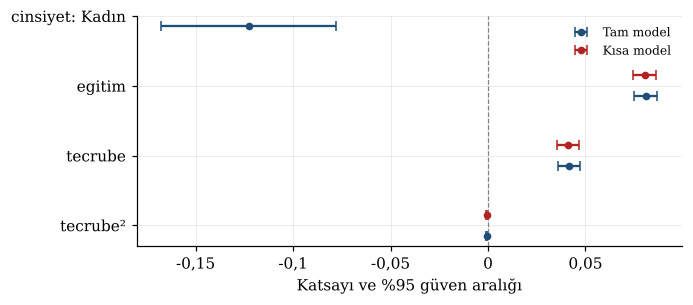

In [2]:
m2 = ek.ekk("np.log(ucret) ~ egitim + tecrube + I(tecrube**2)", ucret, kovaryans="HC1")
ek.katsayi_grafigi(m, m2, adlar=["Tam model", "Kısa model"])   # Stata: coefplot

## 2. Koşullu tahminler: `margins, at()`

"Eğitim 8, 12 ve 16 yıl iken, kadın ve erkek için beklenen log ücret ne?" Diğer değişkenler gözlenen değerlerinde tutulur, standart hatalar delta yöntemiyle hesaplanır.

In [3]:
mj = ek.marjlar(m, at={"egitim": [8, 12, 16]}, grup="cinsiyet")
mj

Tahmin marjları (ortalama tahmin), koşul: egitim, cinsiyet — delta yöntemi
 x:egitim grup:cinsiyet    Marj Std. hata      t       p %95 GA alt %95 GA üst
        8         Erkek 10,6798    0,0179 597,89 <0,0001    10,6447    10,7148
        8         Kadın 10,5569    0,0212 496,97 <0,0001    10,5153    10,5986
       12         Erkek 11,0030    0,0143 771,08 <0,0001    10,9750    11,0310
       12         Kadın 10,8802    0,0175 622,74 <0,0001    10,8459    10,9144
       16         Erkek 11,3262    0,0197 574,08 <0,0001    11,2875    11,3649
       16         Kadın 11,2034    0,0215 522,18 <0,0001    11,1613    11,2455

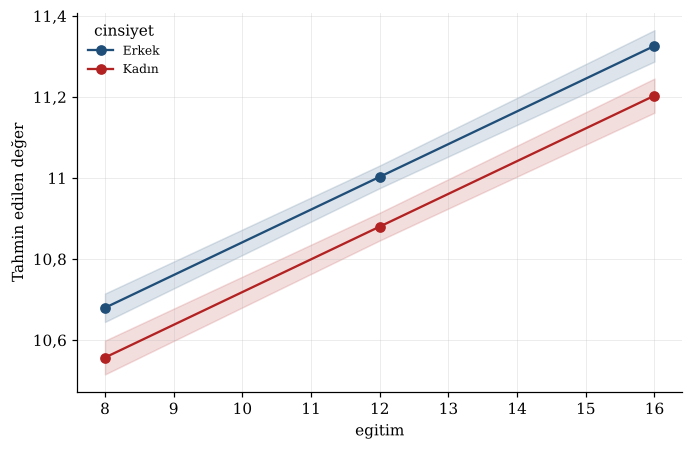

In [4]:
ek.marjinal_grafik(mj)          # Stata: marginsplot

Koşullu marjinal etki: tecrübenin getirisi, tecrübe düzeyine göre nasıl değişiyor? (Kare terim olduğu için etki azalır.)

In [5]:
ek.marjlar(m, dydx="tecrube", at={"tecrube": [5, 20, 35]})

Ortalama marjinal etki: d(tahmin)/d(tecrube), koşul: tecrube — delta yöntemi
 x:tecrube    Etki    Marj Std. hata     t       p %95 GA alt %95 GA üst
         5 tecrube  0,0343    0,0024 14,44 <0,0001     0,0297     0,0390
        20 tecrube  0,0130    0,0009 13,97 <0,0001     0,0112     0,0148
        35 tecrube -0,0084    0,0016 -5,20 <0,0001    -0,0115    -0,0052

## 3. Tabloyu dışa aktarmak

`ek.karsilastir(...).kaydet()` uzantıya göre Word (.docx), LaTeX (.tex, booktabs), Excel (.xlsx), CSV, Markdown ya da HTML yazar. Stata: `esttab m1 m2 using tablo.docx`.

In [6]:
k = ek.karsilastir(m2, m, adlar=["(1)", "(2)"])
k.kaydet("tablo.tex")
print(open("tablo.tex", encoding="utf-8").read()[:600])

\begin{table}[htbp]
\centering
\caption{Model tahmin sonuçlarının karşılaştırılması}
\begin{tabular}{lrr}
\toprule
Değişken & (1) & (2) \\
\midrule
egitim & 0,0803*** & 0,0808*** \\
 & (0,0031) & (0,0031) \\
tecrube & 0,0411*** & 0,0415*** \\
 & (0,0030) & (0,0030) \\
tecrube$^{2}$ & $-$0,000702*** & $-$0,000712*** \\
 & (0,000061) & (0,000060) \\
cinsiyet: Kadın &  & $-$0,1228*** \\
 &  & (0,0228) \\
Sabit & 9,5609*** & 9,6026*** \\
 & (0,0507) & (0,0508) \\
Gözlem sayısı & 1.500 & 1.500 \\
R$^{2}$ & 0,349 & 0,361 \\
Düzeltilmiş R$^{2}$ & 0,347 & 0,359 \\
F & 284,23*** & 221,08*** \\
AIC & 1.


## 4. Sıralı, sayım ve sansürlü modeller

Sınav puanını dört harf notuna çevirip **sıralı logit** tahmin edelim. Kesim noktaları Stata `ologit` ile aynı biçimdedir: P(y ≤ j) = F(kesim_j − xb).

In [7]:
sinav = ek.veri.yukle("sinav")
sinav["not_"] = pd.cut(sinav["puan"], [0, 50, 65, 80, 101], labels=[1, 2, 3, 4]).astype(int)
o = ek.ologit("not_ ~ calisma_saati + uyku + C(burs)", sinav)
o

══════════════════════════════════════════════════════════════════════════════
 Sıralı logit — bağımlı değişken: not_
══════════════════════════════════════════════════════════════════════════════
 Gözlem: 800      Log-olabilirlik: -847,075      Sözde R²: 0,1614
 LR χ²(3) = 325,99 (p <0,0001)   AIC: 1.706,1   BIC: 1.734,3
 Standart hatalar: klasik (OIM)
──────────────────────────────────────────────────────────────────────────────
 Değişken                           Katsayı   Std. hata        z         p
──────────────────────────────────────────────────────────────────────────────
 burs: Evet                          0,5655      0,1534     3,69    0,0002 ***
 calisma_saati                       0,2445      0,0156    15,72   <0,0001 ***
 uyku                                0,2010      0,0595     3,38    0,0007 ***
──────────────────────────────────────────────────────────────────────────────
 /kesim1                             1,6507      0,4537
 /kesim2                             4,

In [8]:
o.marjinal_etkiler().head(8)    # her not için olasılık değişimi (margins, dydx(*))

,değişken,grup,referans,tür,sonuç,AME,std. hata,z,p
0,calisma_saati,,,sürekli,1,-0.025893,0.002157,-12.002403,3.451292e-33
1,calisma_saati,,,sürekli,2,-0.019528,0.001680,-11.620476,3.243249e-31
2,calisma_saati,,,sürekli,3,0.026621,0.001627,16.357642,3.836999e-60
3,calisma_saati,,,sürekli,4,0.018799,0.001439,13.068345,4.993995e-39
4,uyku,,,sürekli,1,-0.021282,0.006371,-3.340644,8.358426e-04
5,uyku,,,sürekli,2,-0.016051,0.004868,-3.297344,9.760375e-04
6,uyku,,,sürekli,3,0.021881,0.006427,3.404653,6.624828e-04
7,uyku,,,sürekli,4,0.015452,0.004651,3.322363,8.925865e-04


**Sayım verisi** (ör. patent, ziyaret, kaza sayısı): `poisson` ve aşırı yayılım varsa `nbreg`. α = 0 için olabilirlik oranı testi otomatik raporlanır. **Sansürlü veri** (ör. 0'da yığılan harcama): `tobit`.

In [9]:
rng = np.random.default_rng(1)
sinav["ders_disi"] = rng.poisson(np.exp(0.2 + 0.05 * sinav["calisma_saati"]) * rng.gamma(2, 0.5, len(sinav)))
nb = ek.nbreg("ders_disi ~ calisma_saati + uyku", sinav)
print(nb)
nb.oranlar()                     # olay oranları (IRR)

══════════════════════════════════════════════════════════════════════════════
 Negatif binom — bağımlı değişken: ders_disi
══════════════════════════════════════════════════════════════════════════════
 Gözlem: 800      Log-olabilirlik: -1.472,222    Sözde R²: 0,0258
 LR χ²(2) = 77,94 (p <0,0001)   AIC: 2.952,4   BIC: 2.971,2
 Standart hatalar: klasik (OIM)
──────────────────────────────────────────────────────────────────────────────
 Değişken                           Katsayı   Std. hata        z         p
──────────────────────────────────────────────────────────────────────────────
 Sabit                              -0,0105      0,2312    -0,05    0,9636 
 calisma_saati                       0,0552      0,0062     8,91   <0,0001 ***
 uyku                                0,0155      0,0309     0,50    0,6165 
──────────────────────────────────────────────────────────────────────────────
 /ln α                              -0,7684      0,1165
 α                                   0,4

,oran,alt,üst
calisma_saati,1.056720,1.043973,1.069623
uyku,1.015605,0.955888,1.079053


In [10]:
sinav["harcama"] = np.maximum(-2 + 0.3 * sinav["calisma_saati"] + rng.normal(scale=2, size=len(sinav)), 0)
ek.tobit("harcama ~ calisma_saati + uyku", sinav, alt=0)

══════════════════════════════════════════════════════════════════════════════
 Tobit — bağımlı değişken: harcama
══════════════════════════════════════════════════════════════════════════════
 Gözlem: 800      Log-olabilirlik: -1.289,491    
 LR χ²(2) = 364,07 (p <0,0001)   AIC: 2.587,0   BIC: 2.605,7
 Standart hatalar: klasik (OIM)
 Sansür: 0,0000 değerinde soldan sansürlü (284 gözlem)
──────────────────────────────────────────────────────────────────────────────
 Değişken                           Katsayı   Std. hata        z         p
──────────────────────────────────────────────────────────────────────────────
 Sabit                              -2,1182      0,4975    -4,26   <0,0001 ***
 calisma_saati                       0,2878      0,0140    20,57   <0,0001 ***
 uyku                                0,0371      0,0658     0,56    0,5728 
──────────────────────────────────────────────────────────────────────────────
 /σ                                  2,0005      0,0659
 var(e)

## 5. Panel birim kök testleri

Panel zaman serisinde durağanlık: `xtunitroot llc` (ortak birim kök), `ips` ve `fisher` (bireysel birim kök). H0 tüm testlerde "birim kök var".

In [11]:
firma = ek.xtset(ek.veri.yukle("firma"), "firma", "yil")
firma["ln_satis"] = np.log(firma["satis"])
ek.panel_birim_kok(firma, "ln_satis", test="ips", gecikme="aic", en_fazla_gecikme=2)

Panel değişkeni: firma (dengeli, 150 birim)
Zaman değişkeni: yil, 2015 – 2024


/tmp/ipykernel_3290/3492000484.py:3: UserWarning: Zaman boyutu (7, 8, 9) düzeltme tablosunun aralığı dışında (10–100); tablonun en yakın değeri kullanıldı. Kısa panelde sonucu temkinli yorumla.
  ek.panel_birim_kok(firma, "ln_satis", test="ips", gecikme="aic", en_fazla_gecikme=2)


Im-Pesaran-Shin (IPS) panel birim kök testi — ln_satis
H0: tüm birimlerde birim kök var  ·  H1: birimlerin bir kısmı durağan
Birim sayısı N = 150 · zaman T = 10 · deterministik: sabit · ADF gecikmesi: ortalama 0,52 (en az 0, en çok 2)

   İstatistik                     Değer         p
   t-bar                        -1,7981          
   W-t-bar                      -3,7368   <0,0001

Im-Pesaran-Shin (IPS) testine göre ln_satis değişkeni için birim kök boş hipotezi reddedilmiştir (W-t-bar = -3,737, p < 0,0001); birimlerin en az bir kısmında seri durağandır.

In [12]:
ek.panel_duraganlik(firma, ["ln_satis"], gecikme=0)   # düzey ve birinci fark, IPS + Fisher

/home/user/ekonometri-tr/src/ekonometri/panel_kok.py:373: UserWarning: Zaman boyutu (9) düzeltme tablosunun aralığı dışında (10–100); tablonun en yakın değeri kullanıldı. Kısa panelde sonucu temkinli yorumla.
  s = panel_birim_kok(d, ad, t, birim, zaman, gecikme=gecikme, deterministik=deterministik)
/home/user/ekonometri-tr/src/ekonometri/panel_kok.py:373: UserWarning: Zaman boyutu (8) düzeltme tablosunun aralığı dışında (10–100); tablonun en yakın değeri kullanıldı. Kısa panelde sonucu temkinli yorumla.
  s = panel_birim_kok(d, ad, t, birim, zaman, gecikme=gecikme, deterministik=deterministik)


,Değişken,Seviye,IPS W-t-bar,IPS p,FISHER Pm,FISHER p
0,ln_satis,Düzey,-7.482373,3.649615e-14,12.652147,5.442958e-37
1,ln_satis,Birinci fark,-35.832044,1.750957e-281,107.085590,0.000000e+00


## 6. Aynısını Stata komutlarıyla

Tüm bu işlemler `ek.Stata()` oturumunda Stata söz dizimiyle de yapılabilir.

In [13]:
s = ek.Stata()
s("sysuse ihracat")
s("varsoc ihracat reel_kur, maxlag(4)")
s("var ihracat reel_kur, lags(1/2)")
s("varstable")

(80 gözlem, 5 değişken: ihracat — simüle eğitim verisi)
Gecikme seçim ölçütleri (örneklem T = 76); * ölçütün seçtiği gecikme
               LL       LR sd        p         FPE      AIC     HQIC     SBIC
Gecikme                                                                      
0        -512,403                       2.594,5749  13,5369  13,5614  13,5983
1        -352,357  320,093  4  <0,0001     42,7244   9,4304  9,5040*  9,6144*
2        -347,157   10,400  4   0,0342     41,4089   9,3989   9,5214   9,7055
3        -342,236   9,842*  4   0,0432    40,4444*  9,3746*   9,5462   9,8040
4        -339,868    4,735  4   0,3155     42,2696   9,4176   9,6382   9,9696


VAR(2) — değişkenler: ihracat, reel_kur · T = 78
Log-olabilirlik = -354,46 · AIC = 9,3451 · HQIC = 9,4661 · SBIC = 9,6473

▸ Denklem: ihracat
   L.ihracat                   0,6543      0,1094     5,98   <0,0001
   L.reel_kur                  0,0482      0,0420     1,15    0,2508
   L2.ihracat                  0,3368      0,1114     3,02    0,0025
   L2.reel_kur                -0,0510      0,0423    -1,21    0,2277
   Sabit                       0,8805      1,8825     0,47    0,6400

▸ Denklem: reel_kur
   L.ihracat                  -0,1561      0,2937    -0,53    0,5951
   L.reel_kur                  0,7988      0,1126     7,09   <0,0001
   L2.ihracat                  0,1433      0,2990     0,48    0,6317
   L2.reel_kur                 0,1330      0,1135     1,17    0,2415
   Sabit                       8,0247      5,0520     1,59    0,1122

Kararlılık: en büyük özdeğer modülü = 0,9938 → kararlı
Eşlik matrisinin özdeğerleri
          Özdeğer  Modül
0  0,9938+0,0000j 0,9938
1  0,9399+0,

,Özdeğer,Modül
0,0.993816+0.000000j,0.993816
1,0.939933+0.000000j,0.939933
2,-0.284909+0.000000j,0.284909
3,-0.195777+0.000000j,0.195777
